# Sketching Before Detail

*The Mathematics of Machine Intelligence · Chapter 18*

Count the passes saved by a rough-first method, sharpen a number level by level, and see what a vote among drafts cannot fix.

These pages illustrate the mathematics. Read the saved figures and calculations in order, or open [the interactive browser edition](reader.html) to change the examples. No code editing is needed. Every figure is computed from the chapter's own equations or from a disclosed simulation; a simulation is not a measurement, and the mathematics of a brain is a model.

Count passes and position-updates before comparing speeds, and remember that a count is not a timing. Check whether a level can overturn an earlier one, because a stack that only adds corrections cannot undo an overshoot. When choosing among several drafts, ask whether the drafts could share a mistake, since agreement measures typicality and not truth.

<details><summary>Reproducing these calculations</summary>

The optional calculation cells use Python with NumPy and Matplotlib. All inputs, random seeds and functions are included in this file. The figures below are saved, so running these cells is optional.

</details>

In [1]:
import io
import math
import re
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from cycler import cycler
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 11, 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#7d8588', 'axes.labelcolor': '#172a3b', 'text.color': '#172a3b', 'xtick.color': '#52606b', 'ytick.color': '#52606b', 'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white', 'grid.alpha': 0.2, 'lines.linewidth': 2, 'svg.fonttype': 'path', 'axes.unicode_minus': False})
plt.rcParams['axes.prop_cycle'] = cycler(color=['#136f75', '#b77518', '#334c72', '#aa4e37', '#677341'])

def clean_display_text(text):
    """Remove signed zero only after an explicitly formatted value rounds to zero."""
    return re.sub(r"(?<![\w.])-(?:0+(?:\.0*)?|\.0+)(?:[eE][+-]?\d+)?(?![\w.])", "0", text)


def display_value(value):
    """One display policy for readers, saved notebooks and skill references."""
    if hasattr(value, "item") and getattr(value, "size", 1) == 1:
        value = value.item()
    if isinstance(value, float):
        if not math.isfinite(value):
            raise ValueError("Return undefined or infinity as a labeled string, not a nonfinite JSON value")
        return "0" if value == 0 else f"{value:.6g}"
    if isinstance(value, str):
        return clean_display_text(value)
    if isinstance(value, (list, tuple)):
        opening, closing = ("(", ")") if isinstance(value, tuple) else ("[", "]")
        return opening + ", ".join(str(display_value(v)) for v in value) + closing
    if isinstance(value, dict):
        return "{" + ", ".join(str(k) + ": " + str(display_value(v)) for k, v in value.items()) + "}"
    return value


"""Chapter 18, Sketching Before Detail: executable mathematics and reader-facing teaching content."""
import math
import re
import numpy as np
import matplotlib.pyplot as plt
NAVY = '#17324d'
TEAL = '#147d86'
GOLD = '#d8a23c'
DARK_GOLD = '#8a5a0f'
TERRA = '#bf6045'
GREY = '#7d8588'

def sig(value, digits=3):
    """Three significant figures; values that are zero up to round-off show as 0."""
    value = float(value)
    if abs(value) < 1e-12:
        return '0'
    return f'{value:.{digits}g}'

def panels():
    fig, axes = plt.subplots(1, 2, figsize=(8, 4.2), layout='constrained')
    for ax in axes:
        ax.grid(alpha=0.15)
    return (fig, axes)

def tag(ax, x, y, text, **kwargs):
    """A label with a white backing so it stays legible over lines."""
    kwargs.setdefault('fontsize', 10)
    kwargs.setdefault('ha', 'center')
    ax.text(x, y, text, bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1.2, 'alpha': 0.9}, **kwargs)

def ring(ax, x, y):
    ax.plot([x], [y], marker='o', markersize=11, markerfacecolor='none', markeredgecolor=NAVY, markeredgewidth=2.2, zorder=6)

def level_sizes(positions):
    """Doubling levels 1, 2, 4, ... up to the full text (the chapter's easy-to-count case)."""
    sizes, size = ([], 1)
    while size < positions:
        sizes.append(size)
        size *= 2
    sizes.append(positions)
    return sizes

def pass_counts(positions, diffusion_passes):
    """Passes and position-updates for three ways of building a text of `positions` positions."""
    levels = level_sizes(positions)
    return {'one at a time': (positions, positions), 'fill everything': (diffusion_passes, diffusion_passes * positions), 'levels': (len(levels), sum(levels))}
PAPER_PASSES = 12

def passes_picture(positions=16, diffusion_passes=8):
    counts = pass_counts(positions, diffusion_passes)
    names = list(counts)
    fig, ax = panels()
    colours = [GREY, GOLD, TEAL]
    labels = ['one at\na time', 'fill\neverything', 'levels']
    x = np.arange(3)
    passes = [counts[n][0] for n in names]
    updates = [counts[n][1] for n in names]
    bars = ax[0].bar(x - 0.2, passes, 0.38, color=colours, label='passes (runs of the model in a row)')
    ax[0].bar(x + 0.2, updates, 0.38, color=colours, alpha=0.45, hatch='//', edgecolor='white', label='position-updates (a toy count of work)')
    for i in range(3):
        tag(ax[0], i - 0.2, passes[i] * 1.12, str(passes[i]), va='bottom', fontsize=9)
        tag(ax[0], i + 0.2, updates[i] * 1.12, str(updates[i]), va='bottom', fontsize=9)
    ax[0].set_yscale('log')
    ax[0].set_xticks(x, labels, fontsize=9)
    ax[0].set(ylabel='count (log scale)', title=f'Building {positions} positions', ylim=(1, 4 * max(updates)))
    ax[0].legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.2))
    grid = np.array([16, 32, 64, 128])
    ax[1].plot(grid, grid, color=GREY, marker='o', linewidth=2, label='one at a time')
    ax[1].plot(grid, [diffusion_passes] * 4, color=GOLD, marker='o', linewidth=2, linestyle='dashed', label=f'fill everything ({diffusion_passes} passes, a setting)')
    ax[1].plot(grid, [len(level_sizes(int(g))) for g in grid], color=TEAL, marker='o', linewidth=2, label='levels that double')
    ax[1].plot([128], [PAPER_PASSES], marker='*', markersize=15, color=TERRA, label='paper: 12 passes for 128 tokens')
    ring(ax[1], positions, counts['levels'][0])
    ax[1].set_xscale('log')
    ax[1].set_yscale('log')
    ax[1].set_xticks(grid, [str(g) for g in grid])
    ax[1].minorticks_off()
    ax[1].set(xlabel='positions in the text', ylabel='passes', title='Passes against length')
    ax[1].legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.2))
    metrics = {'Passes, one at a time': str(passes[0]), 'Passes, fill everything': str(passes[1]), 'Passes, doubling levels': str(passes[2]), 'Position-updates, doubling levels': str(updates[2])}
    summary = f'A text of {positions} positions takes {passes[0]} passes one at a time, {passes[1]} passes of fill-everything ({updates[1]} position-updates) and {passes[2]} passes with doubling levels ({updates[2]} position-updates). These are counts, not timings: real speed also depends on hardware, caching and overhead.'
    calc = f"Doubling levels {', '.join((str(s) for s in level_sizes(positions)))}: {passes[2]} passes, {updates[2]} position-updates. Fill everything: {diffusion_passes} x {positions} = {updates[1]}. One at a time: {positions} passes. For the paper's 128-token text, 12 passes against 128 gives {sig(128 / PAPER_PASSES)} times fewer."
    return (fig, metrics, {'summary': summary, 'calculation': calc})
CODEBOOK_STEPS = [0.5, 0.1, 0.01]

def codebook(step, signed):
    low = -1.0 if signed else 0.0
    count = int(round((1.0 - low) / step)) + 1
    return np.round(low + step * np.arange(count), 10)

def nearest_entry(value, entries):
    return float(entries[int(np.argmin(np.abs(entries - value)))])

def accumulate(target, corrections, start=0.0):
    """Running totals s_k = s_(k-1) + c_k and leftovers r_k = x - s_k for a list of corrections."""
    totals, leftovers, total = ([], [], start)
    for c in corrections:
        total = total + c
        totals.append(total)
        leftovers.append(target - total)
    return (totals, leftovers)

def choose_corrections(target, levels, signed):
    """At each level pick the entry of that level's list nearest to what is still missing."""
    chosen, total = ([], 0.0)
    for step in CODEBOOK_STEPS[:levels]:
        c = nearest_entry(target - total, codebook(step, signed))
        chosen.append(c)
        total += c
    return chosen

def s4(value):
    return sig(value, 4)

def residual_picture(levels=3, target=0.7316, signed=0):
    corrections = choose_corrections(target, levels, bool(signed))
    totals, leftovers = accumulate(target, corrections)
    totals = [0.0] + totals
    leftovers = [target] + leftovers
    fig, ax = panels()
    ax[0].axhline(0, color=GREY, linewidth=1)
    ax[0].plot([target], [0], marker='D', markersize=11, color=GOLD, zorder=5)
    tag(ax[0], target, -0.55, f'target {s4(target)}', fontsize=9, va='top', color=DARK_GOLD)
    for k in range(1, levels + 1):
        ax[0].plot([totals[k - 1], totals[k]], [k - 1, k], color=GREY, linewidth=1.2, zorder=1)
        ax[0].plot([totals[k]], [k], marker='o', markersize=9, color=TEAL, zorder=4)
        tag(ax[0], totals[k], k + 0.3, f's{k} = {s4(totals[k])}', fontsize=9)
        ax[0].plot([target, totals[k]], [k, k], color=TERRA, linewidth=2.2, zorder=2)
    ax[0].plot([0], [0], marker='o', markersize=7, color=GREY)
    ax[0].set(xlim=(-0.05, 1.05), ylim=(-1.0, 3.9), xlabel='number line', yticks=[0, 1, 2, 3], yticklabels=['start', 'level 1', 'level 2', 'level 3'], title='Running total closes in on the target')
    floor = 0.0001
    for tgt, style, colour in [(0.7316, 'solid', TEAL), (0.4216, 'dashed', TERRA), (0.9, 'dotted', GREY)]:
        _, lo = accumulate(tgt, choose_corrections(tgt, 3, bool(signed)))
        values = [abs(tgt)] + [max(abs(v), floor) for v in lo]
        chosen = tgt == target
        ax[1].plot(range(4), values, color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, marker='o', markersize=4, label=f'target {tgt:g}')
    ring(ax[1], levels, max(abs(leftovers[levels]), floor))
    ax[1].set_yscale('log')
    ax[1].set(xlabel='levels used', ylabel='size of the leftover (floor 0.0001)', title='Leftover after each level', ylim=(5e-05, 1.5))
    ax[1].set_xticks(range(4))
    ax[1].legend(fontsize=9, loc='lower left')
    stuck = not signed and levels >= 1 and (totals[1] > target + 1e-09) and (leftovers[levels] < -1e-09)
    metrics = {'Total after the levels used': s4(totals[levels]), 'Leftover (target minus total)': s4(leftovers[levels]), 'Last correction': s4(corrections[levels - 1]) if levels else 'none yet', 'Overshoot that later levels cannot undo': 'yes' if stuck else 'no'}
    lists = "the chapter's lists (nonnegative corrections only)" if not signed else "lists that allow negative corrections (this companion's variation, not in the chapter)"
    summary = f"With {lists}, {levels} level{('' if levels == 1 else 's')} bring{('s' if levels == 1 else '')} the total to {s4(totals[levels])} for a target of {s4(target)}, leaving {s4(leftovers[levels])}. " + ('Level 1 overshot, and later lists only add, so the overshoot stays.' if stuck else 'No levels used yet, so nothing is described.' if levels == 0 else 'Level 1 overshot, but these lists have negative entries, so a later level can pull the total back.' if signed and totals[1] > target + 1e-09 else 'Each level shrinks what the last one left over.')
    calc = 's_k = s_(k-1) + c_k and r_k = x - s_k. ' + '; '.join((f'level {k}: c = {s4(corrections[k - 1])}, s = {s4(totals[k])}, r = {s4(leftovers[k])}' for k in range(1, levels + 1))) + ('.' if levels else 'No levels yet: r_0 = x = ' + s4(target) + '.')
    return (fig, metrics, {'summary': summary, 'calculation': calc})
SET_A = ['The town voted to build the bridge.', 'Town voters approved the new bridge.', 'The town approved a new bridge.', 'The town voted to close the bridge.', 'The town approved a plan to build a new bridge.']
SET_B = ['The town voted to close the old bridge.', 'Town voters chose to close the old bridge.', 'The town closed the old bridge.', 'The town voted to build a new bridge.', 'Voters approved building the new bridge.']
CANDIDATE_SETS = {1: (SET_A, [True, True, True, False, True]), 2: (SET_B, [False, False, False, True, True])}

def words(text):
    return set(re.sub('[^a-z ]', '', text.lower()).split())

def similarity(a, b):
    """Shared words divided by the number of different words in either, ignoring capitals and periods."""
    wa, wb = (words(a), words(b))
    return len(wa & wb) / len(wa | wb)

def mbr_scores(candidates):
    n = len(candidates)
    return [sum((similarity(candidates[i], candidates[j]) for j in range(n) if j != i)) / (n - 1) for i in range(n)]

def mbr_picture(candidate_set=1, selected=3):
    candidates, right = CANDIDATE_SETS[candidate_set]
    scores = mbr_scores(candidates)
    kept = int(np.argmax(scores))
    n = len(candidates)
    fig, ax = panels()
    colours = [TEAL if r else TERRA for r in right]
    bars = ax[0].bar(range(1, n + 1), scores, color=colours, width=0.62, edgecolor=[NAVY if i + 1 == selected else 'none' for i in range(n)], linewidth=3)
    for i, (bar, v) in enumerate(zip(bars, scores)):
        tag(ax[0], i + 1, v + 0.015, sig(v), va='bottom', fontsize=9)
    tag(ax[0], kept + 1, scores[kept] + 0.075, 'kept', va='bottom', color=NAVY, fontsize=11)
    ax[0].set_xticks(range(1, n + 1))
    ax[0].set(xlabel='candidate summary (teal: right, red: wrong)', ylabel='average similarity to the other four', title=f"Set {'AB'[candidate_set - 1]}", ylim=(0, 0.72))
    matrix = np.array([[similarity(candidates[i], candidates[j]) if i != j else np.nan for j in range(n)] for i in range(n)])
    ax[1].imshow(matrix, cmap='Blues', vmin=0, vmax=1, aspect='auto')
    for i in range(n):
        for j in range(n):
            if i != j:
                ax[1].text(j, i, sig(matrix[i, j], 2), ha='center', va='center', fontsize=8, color='white' if matrix[i, j] > 0.6 else NAVY)
    ax[1].add_patch(plt.Rectangle((-0.5, selected - 1.5), n, 1, fill=False, edgecolor=GOLD, linewidth=3))
    ax[1].set_xticks(range(n), [str(i + 1) for i in range(n)])
    ax[1].set_yticks(range(n), [str(i + 1) for i in range(n)])
    ax[1].set(xlabel='other candidate', ylabel='candidate', title='Pairwise similarity (row outlined)')
    ax[1].grid(False)
    shared_mistake = sum((1 for r in right if not r))
    metrics = {'Average similarity of the selected candidate': sig(scores[selected - 1]), 'Candidate MBR keeps': str(kept + 1), 'Kept candidate is': 'right' if right[kept] else 'wrong', 'Candidates that carry the mistake': f'{shared_mistake} of {n}'}
    summary = f"Candidate {selected} agrees with the others by {sig(scores[selected - 1])} on average. MBR keeps candidate {kept + 1} ({sig(scores[kept])}), which is {('right' if right[kept] else 'wrong')}. " + ('Only one candidate is wrong, and it scores lowest.' if candidate_set == 1 else 'Three of five share the mistake, so the typical candidate carries it.')
    others = [j for j in range(n) if j != selected - 1]
    calc = f"Average for candidate {selected} = ({' + '.join((sig(similarity(candidates[selected - 1], candidates[j])) for j in others))}) / {n - 1} = {sig(scores[selected - 1])}. Similarity = shared words / different words in either, ignoring capitals and periods."
    return (fig, metrics, {'summary': summary, 'calculation': calc})
SOLVED = {1: {'NCM': 99.5, 'fill everything (FMLM+)': 98.0, 'one at a time': 14.0}, 2: {'NCM': 96.5, 'fill everything (FMLM+)': 93.0, 'one at a time': 5.0}, 3: {'NCM': 86.1, 'fill everything (FMLM+)': 81.3, 'one at a time': 1.0}}
EXACT = {('NCM', 1), ('NCM', 2), ('NCM', 3), ('fill everything (FMLM+)', 3)}
HARD_EMPTY = 51
LEVEL_NAMES = {1: 'easy', 2: 'medium', 3: 'hard'}

def implied_square_accuracy(solved_fraction, empty_squares):
    """If each empty square were right independently with the same chance p, whole-board success would be p^n."""
    return solved_fraction ** (1.0 / empty_squares)

def sudoku_picture(difficulty=3, empty_squares=51):
    rows = SOLVED[difficulty]
    fig, ax = panels()
    names = list(rows)
    colours = [TEAL, GOLD, GREY]
    bars = ax[0].bar([n.replace(' (', '\n(') for n in names], [rows[n] for n in names], color=colours, width=0.6)
    for bar, n in zip(bars, names):
        approx = '' if (n, difficulty) in EXACT else 'about '
        tag(ax[0], bar.get_x() + bar.get_width() / 2, rows[n] + 2, approx + sig(rows[n], 3), va='bottom', fontsize=9)
    ax[0].set(ylabel='boards solved (percent)', ylim=(0, 115), title=f'Reported, {LEVEL_NAMES[difficulty]} boards (12 passes for NCM)')
    ax[0].tick_params(axis='x', labelsize=8)
    grid = np.linspace(0.85, 1.0, 200)
    for n_empty, style, colour in [(41, 'dotted', GREY), (51, 'solid', TEAL), (61, 'dashed', TERRA)]:
        chosen = n_empty == empty_squares
        ax[1].plot(grid, 100 * grid ** n_empty, color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'{n_empty} empty squares')
    for n, colour in zip(names, colours):
        p = implied_square_accuracy(rows[n] / 100, empty_squares)
        ax[1].plot([p], [rows[n]], marker='o', markersize=8, color=colour, markeredgecolor=NAVY)
    ax[1].set(xlabel='chance each empty square is right (independent)', ylabel='whole board right (percent)', title='A scale, not a measurement', xlim=(0.85, 1.003), ylim=(-3, 103))
    ax[1].legend(fontsize=9, loc='upper left')
    implied = {n: implied_square_accuracy(rows[n] / 100, empty_squares) for n in names}
    metrics = {'NCM solved (percent)': sig(rows['NCM']), 'Implied per-square accuracy, NCM': sig(implied['NCM'], 4), 'Implied per-square accuracy, one at a time': sig(implied['one at a time'], 4), 'Empty squares assumed': str(empty_squares)}
    scale_note = "51 empty squares is the chapter's invented hard board." if difficulty == 3 and empty_squares == HARD_EMPTY else f"Only the chapter's hard example has {HARD_EMPTY} empty squares, so {empty_squares} here is just a scale."
    summary = f"Reported on {LEVEL_NAMES[difficulty]} boards: NCM {sig(rows['NCM'])} percent, the best fill-everything rival {('' if ('fill everything (FMLM+)', difficulty) in EXACT else 'about ')}{sig(rows['fill everything (FMLM+)'])}, one at a time about {sig(rows['one at a time'])}. If squares were independent, NCM's rate needs about {sig(100 * implied['NCM'], 4)} percent per square. {scale_note}"
    calc = f"Whole board = p^n, so p = (solved share)^(1/n). NCM: {sig(rows['NCM'] / 100)}^(1/{empty_squares}) = {sig(implied['NCM'], 4)}. Fill everything (FMLM+): {sig(rows['fill everything (FMLM+)'] / 100)}^(1/{empty_squares}) = {sig(implied['fill everything (FMLM+)'], 4)}. One at a time: {sig(rows['one at a time'] / 100)}^(1/{empty_squares}) = {sig(implied['one at a time'], 4)}. Squares constrain one another in real Sudoku, so these are a scale and not a measurement."
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def majority_correct(n, accuracy, shared_mistake):
    """Chance the majority answer is right: with chance `shared_mistake` every candidate repeats one wrong answer,
    otherwise each candidate is right independently with chance `accuracy` (n odd)."""
    if n % 2 == 0:
        raise ValueError('Use an odd number of candidates so a majority exists.')
    need = n // 2 + 1
    independent = sum((math.comb(n, k) * accuracy ** k * (1 - accuracy) ** (n - k) for k in range(need, n + 1)))
    return (1 - shared_mistake) * independent
ACCURACY = 0.7

def vote_picture(n=5, shared_mistake=0.1):
    p = majority_correct(n, ACCURACY, shared_mistake)
    fig, ax = panels()
    ks = np.arange(0, n + 1)
    independent = np.array([math.comb(n, k) * ACCURACY ** k * (1 - ACCURACY) ** (n - k) for k in ks]) * (1 - shared_mistake)
    mass = independent.copy()
    mass[0] += shared_mistake
    need = n // 2 + 1
    colours = [TEAL if k >= need else GREY for k in ks]
    ax[0].bar(ks, independent, color=colours, width=0.7)
    if shared_mistake > 0:
        ax[0].bar([0], [shared_mistake], bottom=[independent[0]], color=TERRA, width=0.7, label='all repeat one mistake')
        ax[0].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2))
    ax[0].set(xlabel=f'candidates giving the right answer (of {n}); teal: majority right', ylabel='chance', title='Spread of right answers')
    if n <= 15:
        ax[0].set_xticks(ks)
    grid = [1, 3, 5, 9, 15, 31]
    for c, style, colour in [(0.0, 'dotted', GREY), (0.1, 'solid', TEAL), (0.3, 'dashed', TERRA)]:
        chosen = c == shared_mistake
        ax[1].plot(range(len(grid)), [majority_correct(g, ACCURACY, c) for g in grid], color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, marker='o', markersize=4, label=f'shared mistake {c:g}')
        ax[1].axhline(1 - c, color=NAVY if chosen else colour, linewidth=0.8, linestyle='dotted')
    ring(ax[1], grid.index(n), p)
    ax[1].set_xticks(range(len(grid)), [str(g) for g in grid])
    ax[1].set(xlabel='candidates voting', ylabel='chance the majority is right', title='Constructed model: the vote ceiling', ylim=(0.4, 1.03))
    ax[1].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=3)
    ceiling = 1 - shared_mistake
    metrics = {'Majority right': sig(p), 'A single candidate is right': sig((1 - shared_mistake) * ACCURACY), 'Ceiling however many vote': sig(ceiling)}
    summary = f"Each candidate is right with chance {ACCURACY:g} when the errors are independent; with chance {shared_mistake:g} all of them repeat one mistake. {n} voter{('s' if n != 1 else '')} reach{('es' if n == 1 else '')} {sig(p)}, and no number of voters can beat {sig(ceiling)}. This is the companion's constructed model, not a result from the paper."
    calc = f'P(majority right) = (1 - {shared_mistake:g}) x sum from k = {need} to {n} of C({n}, k) x {ACCURACY:g}^k x {1 - ACCURACY:g}^({n} - k) = {sig(p)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
NAVON = {'small': [664.0, 573.0, 581.0], 'big': [462.0, 471.0, 477.0]}
TASK_NAMES = {'small': 'name the small letters', 'big': 'name the big letter'}

def navon_gap(times):
    """The slowest condition minus the mean of the other two."""
    ordered = sorted(times, reverse=True)
    return ordered[0] - float(np.mean(ordered[1:]))

def navon_picture(task=1):
    key = 'small' if task == 1 else 'big'
    times = NAVON[key]
    fig, ax = panels()
    order = sorted(times, reverse=True)
    bars = ax[0].bar(['slowest', 'middle', 'fastest'], order, color=[TERRA, GOLD, TEAL], width=0.6)
    for bar, v in zip(bars, order):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, v + 8, sig(v, 3), va='bottom')
    ax[0].set(ylabel='mean reaction time (milliseconds)', ylim=(0, 780), title=f'Task: {TASK_NAMES[key]}')
    gaps = {k: navon_gap(v) for k, v in NAVON.items()}
    names = ['small letters', 'big letter']
    bars = ax[1].bar(names, [gaps['small'], gaps['big']], color=[TEAL, GOLD], width=0.5)
    for bar, v in zip(bars, [gaps['small'], gaps['big']]):
        tag(ax[1], bar.get_x() + bar.get_width() / 2, v + 3, sig(v, 3), va='bottom')
    ring(ax[1], 0 if key == 'small' else 1, gaps[key])
    ax[1].set(ylabel='slowest minus mean of the other two (ms)', title='Slowest minus mean of the other two', ylim=(0, 105), xlabel='task')
    metrics = {'Slowest condition (ms)': sig(order[0]), 'Mean of the other two (ms)': sig(np.mean(order[1:]), 4), 'Gap (ms)': sig(gaps[key])}
    if key == 'small':
        summary = 'Naming the small letters took 664 ms in one condition and 573 and 581 ms in the other two, a gap of about 87 ms. The chapter ties the slow one to a big letter that differed from the small ones, but does not say which of 573 and 581 is which. Navon noted the big letter is also simply larger.'
    else:
        summary = 'Naming the big letter took 462, 471 and 477 ms, a spread of about 10.5 ms (slowest minus the mean of the other two). The chapter reports no reliable slowing, and its sources do not say which number goes with which condition, so this is a spread among three numbers, not shown to be interference.'
    calc = f'Gap = slowest - mean of the other two = {sig(order[0])} - ({sig(order[1])} + {sig(order[2])})/2 = {sig(gaps[key])} ms.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

## C18-D01: How many passes does it take to build a text?

A 16-position text can be built one position at a time, by filling every position in several passes, or level by level. How many passes and position-updates does each take?

One at a time, each pass picks one token using everything before it, so a text takes as many passes in a row as it has tokens. Filling everything repeats a pass over all positions. Levels start with a rough version of the whole text with very few positions and each later level adds detail, so the number of passes equals the number of levels: log2 of the length plus 1 in this doubling toy, and a fixed 12 in the paper.

$$
\text{passes}_{\text{levels}}=\lceil\log_2 L\rceil+1,\qquad \text{updates}_{\text{levels}}=1+2+4+\cdots+L=2L-1
$$

**Symbols:** L: the number of positions in the text (a power of two here, for easy counting); pass: one run of the model; one level is one pass; position-update: one position computed in one pass

**Predict before looking:** For 16 positions and 8 fill-everything passes, predict which method makes the most position-updates and which makes the fewest.

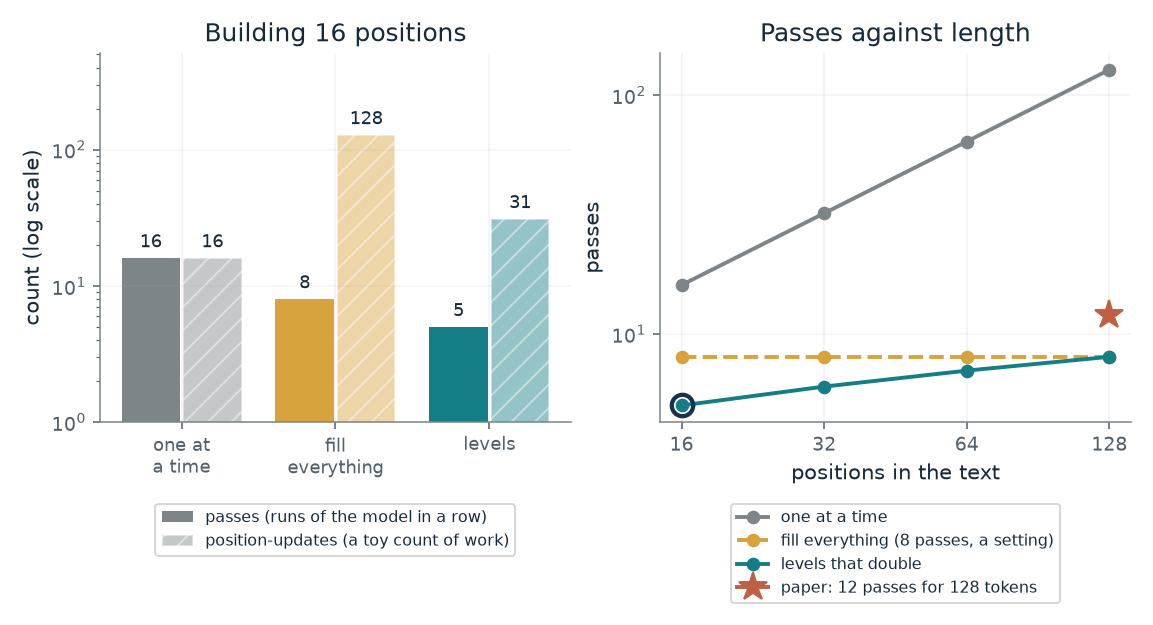

- **Passes, one at a time:** 16
- **Passes, fill everything:** 8
- **Passes, doubling levels:** 5
- **Position-updates, doubling levels:** 31

A text of 16 positions takes 16 passes one at a time, 8 passes of fill-everything (128 position-updates) and 5 passes with doubling levels (31 position-updates). These are counts, not timings: real speed also depends on hardware, caching and overhead.

Doubling levels 1, 2, 4, 8, 16: 5 passes, 31 position-updates. Fill everything: 8 x 16 = 128. One at a time: 16 passes. For the paper's 128-token text, 12 passes against 128 gives 10.7 times fewer.

In [2]:
figure, values, explanation = passes_picture(**{'positions': 16, 'diffusion_passes': 8})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How many passes does it take to build a text?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Positions in the text = 16, Passes of fill-everything = 8: One at a time takes 16 passes and 16 position-updates. Fill-everything takes 8 passes but 128 position-updates. Doubling levels of 1, 2, 4, 8 and 16 take 5 passes and 31 position-updates. At 128 positions the paper's real schedule is 12 passes, not the 8 that doubling would give.

**Takeaway:** A rough-first method can need far fewer passes than writing one piece at a time, and fewer position-updates than filling everything repeatedly, but counts are not timings.

**Why it matters:** Writing one token per pass makes a text take as many passes in a row as it has tokens. Building in levels changes that count, which is why the method is worth studying, and the count does not say how fast any real system runs.

**In brains and behavior:** No brain data are involved. The chapter does not claim that people think this way.

**In machines:** Left-to-right decoding takes one pass per token. The Stanford model writes a 128-token text in 12 passes, each pass choosing a whole level of codes, and the authors report it ran 21 times faster than a rival at 128 passes, by their own timing.

**Where it applies:** Passes and position-updates would have equal costs, which they do not: actual speed and total computing also depend on architecture, caching, hardware and other overhead. The paper's levels do not double; its main Sudoku configuration begins with one, two and four codes and grows more slowly.

**Check your understanding:** How many passes and position-updates does a 64-position text take with doubling levels?

<details><summary>Show the answer</summary>

Levels of 1, 2, 4, 8, 16, 32 and 64 give 7 passes and 1 + 2 + 4 + 8 + 16 + 32 + 64 = 127 position-updates.

</details>

*Source: Chapter 18, A model that writes one piece at a time commits early. The chapter's invented 16-position text: 16 passes one at a time; 8 passes of fill-everything, 8 x 16 = 128 position-updates; 5 doubling levels, 31 position-updates. The other lengths and pass settings are this companion's variations. The reported 12 passes for a 128-token text and the authors' 21 times timing (against DUO at 128 passes, on one H100) are the paper's; the chapter says the doubling is only for easy counting.*

## C18-D02: Can a later level undo an earlier one?

A target of 0.7316 is described in three levels, each choosing one entry from a list. What are the totals and leftovers, and what happens when level 1 overshoots?

At each level the closest entry to what is still missing is added to the running total. The leftover after level k is the target minus that total, so each new leftover is the old one minus the new correction. Lists with finer steps shrink the leftover. If the first pick overshoots and the later lists contain no negative entries, nothing can pull the total back.

$$
s_k=s_{k-1}+c_k,\qquad r_k=x-s_k
$$

**Symbols:** x: the target; k: the level number; c_k: the correction chosen at level k: the list entry nearest to what is still missing; s_k: the running total after level k, starting at s_0 = 0; r_k: the leftover (residual) after level k

**Predict before looking:** For a target of 0.4216 with the chapter's lists, predict whether three levels reach it as closely as they reach 0.7316.

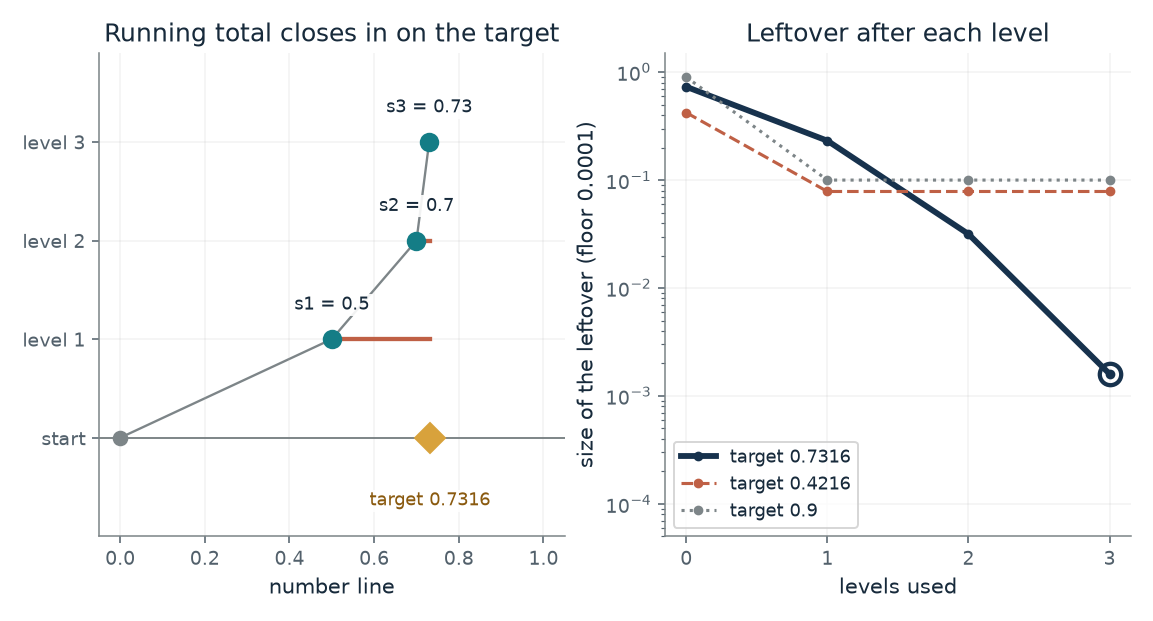

- **Total after the levels used:** 0.73
- **Leftover (target minus total):** 0.0016
- **Last correction:** 0.03
- **Overshoot that later levels cannot undo:** no

With the chapter's lists (nonnegative corrections only), 3 levels bring the total to 0.73 for a target of 0.7316, leaving 0.0016. Each level shrinks what the last one left over.

s_k = s_(k-1) + c_k and r_k = x - s_k. level 1: c = 0.5, s = 0.5, r = 0.2316; level 2: c = 0.2, s = 0.7, r = 0.0316; level 3: c = 0.03, s = 0.73, r = 0.0016.

In [3]:
figure, values, explanation = residual_picture(**{'levels': 3, 'target': 0.7316, 'signed': 0})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Can a later level undo an earlier one?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Levels used = 3, Target = 0.7316, Lists allow negative corrections = 0: For 0.7316 the totals are 0.5, 0.7 and 0.73, and the leftover falls from 0.2316 to 0.0316 to 0.0016. Now switch to the target 0.4216: level 1 picks 0.5, overshooting, and since later lists only add, the total stays at 0.5 with leftover -0.0784. Allow negative corrections (the companion's own variation, not in the chapter) and the same target ends at 0.42.

**Takeaway:** Stacked lists close in on a target when each level can correct what the last one missed, and an early overshoot is permanent when later levels can only add (the chapter's lists; allowing negative corrections is the companion's variation).

**Why it matters:** A rough-first method has to commit to something at each level. Whether later levels may overturn an earlier one decides whether early mistakes can be repaired, which is the question the Sudoku result bears on.

**In machines:** In the paper, each level encodes the residual left by the earlier ones, and the finer levels are cut off at random in training so that early levels carry real information. The accounting here is a specification of that idea on one number; it is not how the model chooses its codes.

**Where it applies:** Each level picks the entry nearest to the leftover. With the chapter's lists, which run from 0 to 1, a later level can only add, so an overshoot at level 1 stays; the chapter notes that whether later levels can overturn an earlier one is what the Sudoku result bears on. A correction chosen by this rule is not shown to be what any model does.

**Check your understanding:** For target 0.9 with the chapter's lists, what does level 1 pick, and what is the leftover after three levels?

<details><summary>Show the answer</summary>

Level 1 picks 1.0, the nearest of 0, 0.5 and 1, so the total is 1 and the leftover is -0.1. Later lists contain only nonnegative entries and pick 0, so the leftover stays at -0.1.

</details>

*Source: Chapter 18, Fix the leftover, one level at a time. The chapter's constructed example (not from the paper): target 0.7316, level 1 multiples of 0.5 from 0 to 1, level 2 multiples of 0.1, level 3 multiples of 0.01, giving corrections 0.5, 0.2, 0.03, totals 0.5, 0.7, 0.73 and leftovers 0.2316, 0.0316, 0.0016. The other two targets, and the option of lists that allow negative corrections, are this companion's variations.*

## C18-D03: Which draft does minimum Bayes risk keep?

A model writes five one-line summaries of a vote. If we keep the one most like the others, is it the right one?

For each candidate, average its similarity to the other four. The kept candidate is the one with the highest average. In set A four of five drafts are right and they resemble each other, so the typical one is right and the odd one out scores lowest. In set B three drafts say the same wrong thing and so resemble each other most.

$$
i^{*}=\arg\max_{i}\ \frac{1}{n-1}\sum_{j\ne i}\operatorname{sim}(y_i,y_j),\qquad \hat y=y_{i^{*}}
$$

**Symbols:** y_1 ... y_n: the n candidate drafts (five here); sim(y_i, y_j): word overlap: shared words divided by the number of different words in either, ignoring capitals and periods; i*: the candidate with the largest average similarity to the others; y-hat: the candidate kept

**Predict before looking:** In set B three of five candidates share a mistake. Predict whether MBR keeps a right candidate.

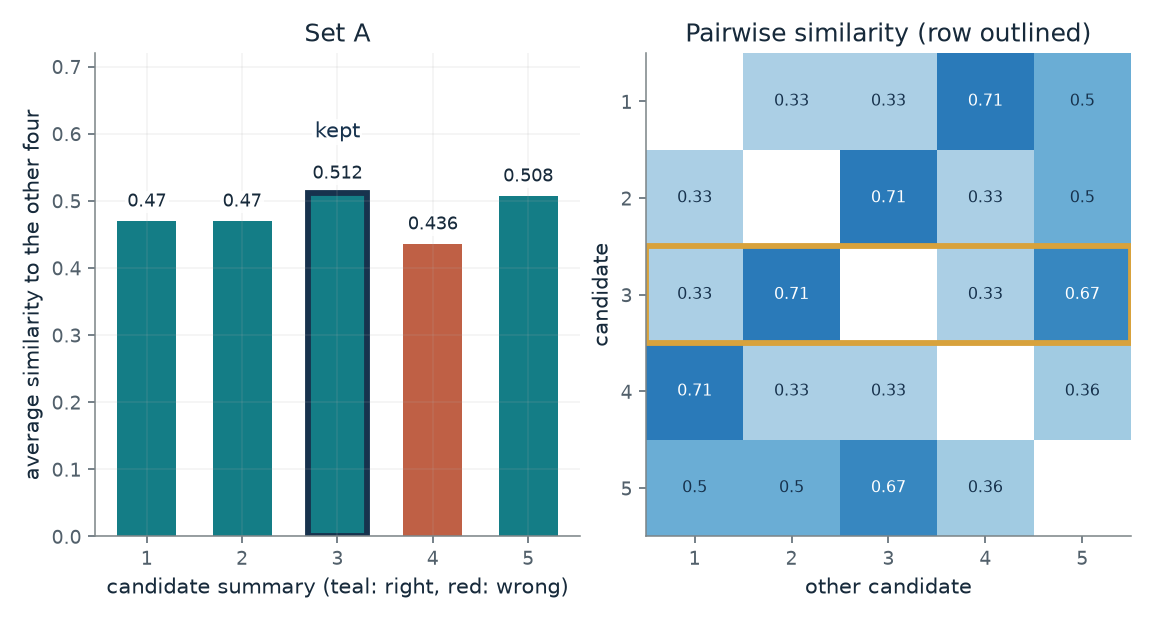

- **Average similarity of the selected candidate:** 0.512
- **Candidate MBR keeps:** 3
- **Kept candidate is:** right
- **Candidates that carry the mistake:** 1 of 5

Candidate 3 agrees with the others by 0.512 on average. MBR keeps candidate 3 (0.512), which is right. Only one candidate is wrong, and it scores lowest.

Average for candidate 3 = (0.333 + 0.714 + 0.333 + 0.667) / 4 = 0.512. Similarity = shared words / different words in either, ignoring capitals and periods.

In [4]:
figure, values, explanation = mbr_picture(**{'candidate_set': 1, 'selected': 3})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Which draft does minimum Bayes risk keep?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Set of candidates = 2, Candidate to examine = 1: In set B, candidate 1 scores 0.462, the highest, and it carries the shared mistake 'close the old bridge'; the two right summaries score 0.352 and 0.237. In set A, candidate 3 scores 0.512 and is right, and the wrong candidate 4 scores lowest at 0.436.

**Takeaway:** MBR keeps the most typical candidate, not the best one. When drafts tend to repeat a mistake, the typical draft carries it.

**Why it matters:** Drawing several drafts is cheap when each draw is cheap, but choosing among them by agreement only rewards what the drafts share, true or not.

**In brains and behavior:** No brain data are involved.

**In machines:** In the paper, 16 candidates on XSum raised the summary score from 28.0 to 29.6, and 12 on translation raised the BLEU score from 22.6 to 25.2. The chapter says the paper's similarity measure is not stated, and a shared mistake can win by definition.

**Where it applies:** Whether a candidate is right or wrong is set by the chapter, not computed. The method has no answer key and no outside judge. It keeps the candidate that agrees most, on average, with the others.

**Check your understanding:** In set A, candidate 3 scores 0.333, 0.714, 0.333 and 0.667 against candidates 1, 2, 4 and 5. What is its average?

<details><summary>Show the answer</summary>

(0.333 + 0.714 + 0.333 + 0.667) / 4 = 2.047/4 = 0.512.

</details>

*Source: Chapter 18, Drawing several and keeping the most typical. The chapter's two constructed sets of five one-line summaries of a bridge vote, with its word-overlap similarity. In set A candidate 4 is wrong; in set B candidates 1, 2 and 3 share the mistake 'close the old bridge'. The chapter's scores are reproduced: 0.512 for candidate 3 in set A, 0.436 for candidate 4, and 0.462 for candidate 1 in set B. The paper's own similarity measure for this step is not stated.*

## C18-D04: How did the reported Sudoku results compare, and what would they imply per square?

The preprint reports the share of boards solved by three kinds of model. How much per-square accuracy would those shares imply if squares were independent?

If each of n empty squares were right independently with chance p, the whole board would be right with chance p to the n. Taking the nth root of a reported solve rate gives the per-square accuracy it would need. The figure is a scale for how quickly a single early error ruins a board; real squares depend on one another.

$$
P(\text{board right})=p^{\,n}\quad\Longrightarrow\quad p=\bigl(P(\text{board right})\bigr)^{1/n}
$$

**Symbols:** n: the number of empty squares (51 on the chapter's invented board with 30 given digits); p: the chance each empty square is right, if squares were independent; P(board right): the share of boards solved, counted only if all 81 squares are right

**Predict before looking:** Predict which of the three methods needs the highest per-square accuracy to produce its hard-board result, if squares were independent.

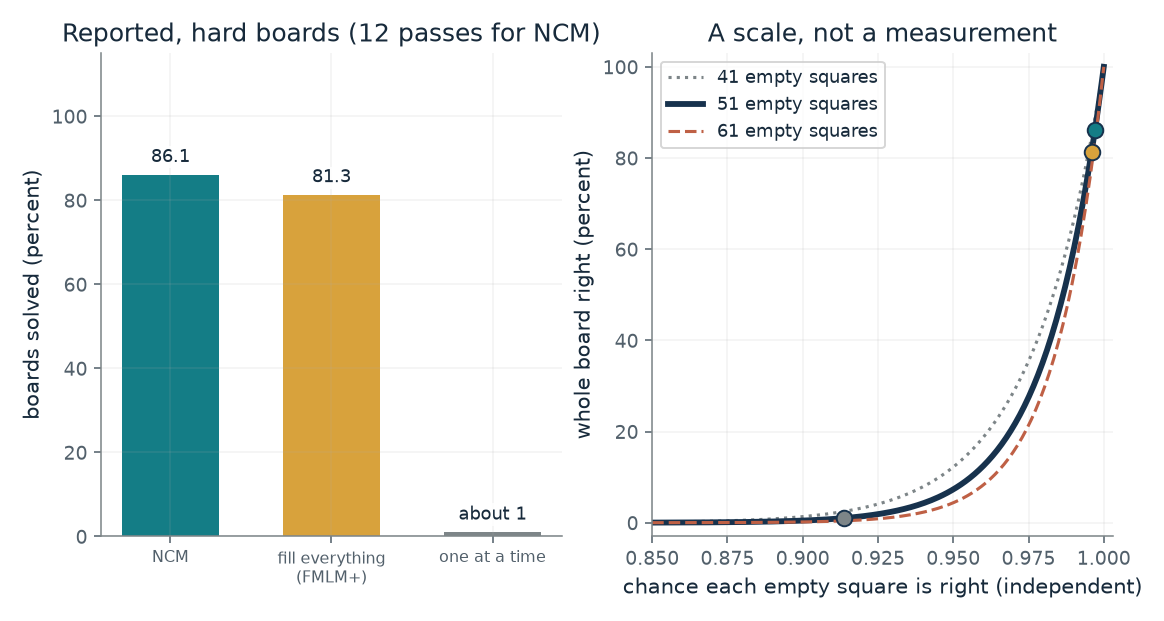

- **NCM solved (percent):** 86.1
- **Implied per-square accuracy, NCM:** 0.9971
- **Implied per-square accuracy, one at a time:** 0.9137
- **Empty squares assumed:** 51

Reported on hard boards: NCM 86.1 percent, the best fill-everything rival 81.3, one at a time about 1. If squares were independent, NCM's rate needs about 99.71 percent per square. 51 empty squares is the chapter's invented hard board.

Whole board = p^n, so p = (solved share)^(1/n). NCM: 0.861^(1/51) = 0.9971. Fill everything (FMLM+): 0.813^(1/51) = 0.9959. One at a time: 0.01^(1/51) = 0.9137. Squares constrain one another in real Sudoku, so these are a scale and not a measurement.

In [5]:
figure, values, explanation = sudoku_picture(**{'difficulty': 3, 'empty_squares': 51})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How did the reported Sudoku results compare, and what would they imply per square?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Board difficulty = 3, Empty squares on a board = 51: On hard boards NCM solved 86.1 percent, which would need about 99.7 percent per square across 51 squares, if squares were independent. The left-to-right model's about 1 percent would need only about 91.4 percent per square. On this scale, a per-square gap of about 0.1 point already separates NCM (0.9971) from FMLM+ (0.9959, from 81.3 percent) by about 5 points of boards.

**Takeaway:** Whole-board success compounds over many squares. On an independent-squares scale, a per-square gap of about 0.1 point (0.9971 against 0.9959, NCM against FMLM+) turns 86.1 into 81.3 percent, and a gap of several points (0.9971 against 0.9137) separates 86.1 from about 1 percent.

**Why it matters:** A rough-first method that lets later levels correct earlier partial solutions is the authors' explanation for the Sudoku gap. The chapter says that explanation is a guess and that the paper reports no test isolating the cause.

**In brains and behavior:** No brain data are involved; the chapter says it does not claim that people solve Sudoku this way.

**In machines:** A left-to-right model commits to each square as it goes. The preprint's model keeps a rough picture of the whole board and sharpens it. The paper reports its Sudoku results and does not test the cause.

**Where it applies:** A board counts as solved only if all 81 squares are right. The independence assumption is false for Sudoku, where a digit in one place limits digits in many others, so the implied accuracies are a scale and not a measurement. The 51 empty squares are the chapter's invented hard board (30 given digits). The chapter says easier boards give more digits and does not say how many digits the preprint's boards give, so for easy and medium boards, and for 41 or 61 squares, the empty-square setting is only a scale. The preprint reports one training seed and no error bars, and an outside reproduction reported 86.3 percent on 2,000 hard boards without retraining the model or reproducing the baselines.

**Check your understanding:** If squares were independent and 51 were empty, what per-square accuracy gives 86.1 percent of boards?

<details><summary>Show the answer</summary>

0.861 raised to the power 1/51 is about 0.99707, so about 99.7 percent per square.

</details>

*Source: Chapter 18, On Sudoku, later levels corrected earlier ones. Reported results, from the chapter: Next-Concept Modeling (NCM) solved 99.5, 96.5 and 86.1 percent of easy, medium and hard boards in 12 passes. The best fill-everything rival (FMLM+) solved about 98 and 93 percent on easy and medium boards and 81.3 on hard (the chapter's opening gives the exact figure), and a left-to-right model about 14, 5 and 1. The rival numbers were copied from another group's paper. The independent-squares arithmetic is this companion's, not the paper's; the paper does not say how many boards were tested.*

## C18-D05: What can a vote among drafts never repair?

Majority voting over final answers is MBR with the simplest similarity. How many voters does it take, and what stops it?

When errors are independent, the majority of many candidates is right almost surely if each is right more often than not. A shared mistake is different: the candidates all say the same wrong thing, so the vote reports it with confidence. The two cases add up in proportion to their chances, so the vote's success has a ceiling of one minus the shared-mistake chance.

$$
P(\text{majority right})=(1-c)\sum_{k=\lceil n/2\rceil}^{n}\binom{n}{k}a^{k}(1-a)^{n-k}
$$

**Symbols:** n: the number of candidate answers (odd, so a majority exists); a: the chance each candidate is right when errors are independent (0.7 here); c: the chance that all candidates repeat one shared mistake

**Predict before looking:** At a shared-mistake chance of 0.1, predict whether 31 voters beat 0.95.

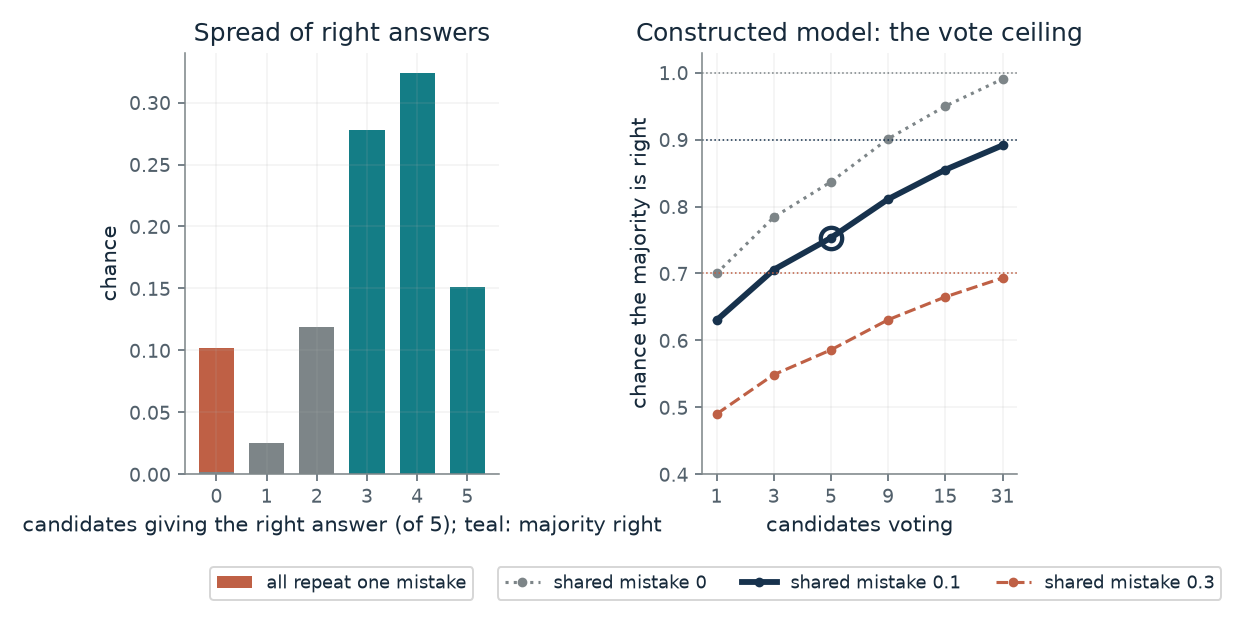

- **Majority right:** 0.753
- **A single candidate is right:** 0.63
- **Ceiling however many vote:** 0.9

Each candidate is right with chance 0.7 when the errors are independent; with chance 0.1 all of them repeat one mistake. 5 voters reach 0.753, and no number of voters can beat 0.9. This is the companion's constructed model, not a result from the paper.

P(majority right) = (1 - 0.1) x sum from k = 3 to 5 of C(5, k) x 0.7^k x 0.3^(5 - k) = 0.753.

In [6]:
figure, values, explanation = vote_picture(**{'n': 5, 'shared_mistake': 0.1})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='What can a vote among drafts never repair?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Candidates voting = 31, Chance all candidates repeat one mistake = 0.1: With 31 voters the independent part is almost surely right, but the majority can be right only when there is no shared mistake, so it cannot pass 0.9. At shared-mistake chance 0.3 the ceiling is 0.7. These numbers come from the companion's constructed model (a = 0.7, c made up), not from the paper. More drafts help with scatter and cannot help with a repeated mistake.

**Takeaway:** In this constructed model, more voters wash out independent errors but cannot remove a mistake all of them repeat, so a settled tally is stable and not necessarily true.

**Why it matters:** A system that draws many answers from one model tends to treat agreement as evidence. How related the errors are decides whether the vote can improve on a single answer.

**In brains and behavior:** No brain data are involved.

**In machines:** Self-consistency votes over sampled final answers. In this toy the vote's ceiling is set by the chance of a shared mistake, a quantity the chapter says to ask about and does not measure.

**Where it applies:** Two kinds of answer (right or wrong), independent errors when there is no shared mistake, and a shared mistake that makes every candidate wrong together. Real answers from one model are related in more complicated ways.

**Check your understanding:** With a = 0.7, c = 0 and n = 3, what is the chance the majority is right?

<details><summary>Show the answer</summary>

3 x 0.7^2 x 0.3 + 0.7^3 = 0.441 + 0.343 = 0.784.

</details>

*Source: Chapter 18, Drawing several and keeping the most typical. The chapter states that majority voting over final answers is MBR with similarity 1 for the same answer and 0 for a different one, that a settled tally is stable and not necessarily true, and that several answers from one model are less independent than they look (Chapter 23's sunny-window thermometers). The two-answer model with a shared-mistake chance is this companion's construction, with made-up numbers (a = 0.7, c from 0 to 0.3); it is not from the paper or from the cited work on self-consistency.*

## C18-D06: How large was the slowest-condition gap in Navon's timings?

People named either the big letter or the small letters of a figure. In which task did the other level slow them down?

Each task has three conditions, and the chapter gives their mean times. The gap compares the slowest with the mean of the other two. Naming small letters had a large gap and naming the big letter had a small one, the asymmetry Navon read as the big shape coming first. The sources do not label the conditions for the big-letter task, so its 10.5 ms is a spread, not a shown effect.

$$
\text{gap}=t_{\text{slowest}}-\tfrac{1}{2}\left(t_{\text{other 1}}+t_{\text{other 2}}\right)
$$

**Symbols:** t: mean reaction time in milliseconds for one condition; gap: how much longer the slowest condition took than the average of the other two (milliseconds)

**Predict before looking:** Predict which task shows the larger gap, and whether it fits a global-first order of processing.

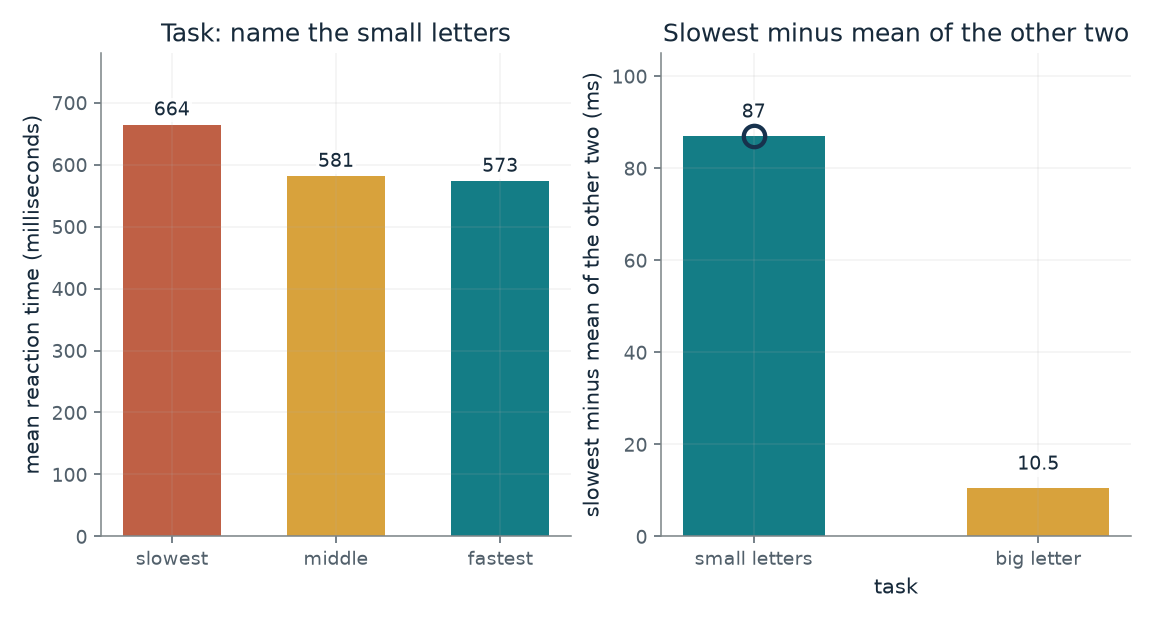

- **Slowest condition (ms):** 664
- **Mean of the other two (ms):** 577
- **Gap (ms):** 87

Naming the small letters took 664 ms in one condition and 573 and 581 ms in the other two, a gap of about 87 ms. The chapter ties the slow one to a big letter that differed from the small ones, but does not say which of 573 and 581 is which. Navon noted the big letter is also simply larger.

Gap = slowest - mean of the other two = 664 - (581 + 573)/2 = 87 ms.

In [7]:
figure, values, explanation = navon_picture(**{'task': 1})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt="How large was the slowest-condition gap in Navon's timings?"))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Task = 1: Naming the small letters, the slowest condition took 664 ms against about 577 for the others (the chapter says about 575), a gap of about 87 ms. Naming the big letter, the three conditions ranged from 462 to 477 ms and the chapter reports no reliable slowing. Navon read that asymmetry as the big shape coming first, with the caveat that the big letter is also larger.

**Takeaway:** In these timings a different big letter slowed naming the small letters, and the small letters did not reliably slow naming the big one (the chapter's reading; Navon noted the big letter is also larger).

**Why it matters:** The studies in this chapter concern the order in which information becomes usable. The chapter says none tests a whole level of positions produced at once and then a finer level, so the link to the machine method is an analogy this book draws.

**In brains and behavior:** This is a reaction-time result in 14 undergraduates. In 1997 Oliva and Schyns showed that the task can flip which level dominates, and in 2021 Wiesmann and colleagues found the evidence did not support a default rough-first strategy.

**In machines:** The Stanford model's early levels are rough and its last level is exact. The chapter says the order in which people's information arrives is not that algorithm.

**Where it applies:** The gap is a difference of means from 14 people and says nothing about reliability, which the original reports and this companion does not compute. Navon noted that the big letter is also simply larger, which could explain the result. The study shows which information was usable faster, not what any mind experienced.

**Check your understanding:** For the big-letter task, what is the slowest time minus the mean of the other two?

<details><summary>Show the answer</summary>

477 - (462 + 471)/2 = 477 - 466.5 = 10.5 ms, small beside the 87 ms of the small-letter task.

</details>

*Source: Chapter 18, A rough whole shows up before fine detail, but not always. Reported result: Navon (1977), Experiment 3, 14 undergraduates, 40 ms masked display, as the chapter lists it: 664, 573 and 581 ms when naming the small letters; 462, 471 and 477 ms when naming the big letter. The chapter says 664 against about 575 otherwise when the big letter differed. The chapter's sources do not say which of the other numbers goes with which condition, so only the slowest-minus-the-others gap is computed here, and that is this companion's summary.*

## Bring it to your own question

Count passes and position-updates before comparing speeds, and remember that a count is not a timing. Check whether a level can overturn an earlier one, because a stack that only adds corrections cannot undo an overshoot. When choosing among several drafts, ask whether the drafts could share a mistake, since agreement measures typicality and not truth.

Use the `mmi-ch18-sketching-before-detail` skill to choose a relevant equation, work with your inputs, and interpret the result. The skill should explain the assumptions and distinguish an illustration from evidence about your particular situation.